# Calculus of variations 3: The principle of least action

*Learning path: calculus of variations, part 3 of 3.* [Index](README.md) · Previous: [Hanging chains and soap films](02-hanging-chains-and-soap-films.ipynb)

Throw a ball and it flies along a parabola. Newton explains this with forces: gravity pulls down, so the velocity
changes at a steady rate. In 1744 Pierre-Louis Maupertuis proposed a different explanation: nature is economical,
and among all the ways the ball could go from here to there in a given time, it takes the one that makes a certain
quantity, the **action**, as small as possible. Euler made the idea precise, Lagrange built all of mechanics on it
(*Mécanique analytique*, 1788), and William Rowan Hamilton gave it its modern form in 1834.

The principle of least action turns out to be deeper than Newton's laws. It works in any coordinates (angles, polar
coordinates, anything), it explains why energy and momentum are conserved, and it carries over unchanged to
electromagnetism, relativity and quantum mechanics (Feynman's path integral). This lesson shows how.

**Who this is for.** Students who have done [lesson 1](01-shortest-paths-and-the-fastest-slide.ipynb) and know Newton's
law $F = ma$.

**What you will be able to do afterwards:**

1. write the Lagrangian $L = T - V$ of a simple mechanical system;
2. check that the true motion makes the action stationary, and get Newton's law from `eulerlagrange`;
3. find conserved quantities: energy when $L$ has no $t$, momentum when a coordinate is missing (Noether);
4. simulate a system straight from its Lagrangian with `motion`;
5. see chaos in the double pendulum.

Plan about 60 minutes. Each section ends with a **Try this**; exercises, hints and answers are at the end.

## 1. The action of a thrown ball

For a particle the **Lagrangian** is kinetic minus potential energy, $L = T - V$, and the **action** of a path is
$S = \int L\,dt$. A ball of mass 1 thrown straight up has height $y(t)$, $T = \tfrac12 y'^2$ and $V = g y$. Suppose
it leaves the hand at $t = 0$ and comes back at $t = 2$. The true path is the parabola $y = \tfrac{g}{2}t(2 - t)$.
Compare its action with some other paths with the same start and end:

In [1]:
eval(action(y'^2/2 - 9.81*y, y, t, 9.81*t*(2 - t)/2, 0, 2), 5)
eval(action(y'^2/2 - 9.81*y, y, t, 0.8*9.81*t*(2 - t)/2, 0, 2), 5)
eval(action(y'^2/2 - 9.81*y, y, t, 1.2*9.81*t*(2 - t)/2, 0, 2), 5)
eval(action(y'^2/2 - 9.81*y, y, t, 9.81*t*(2 - t)/2 + sin(pi*t), 0, 2), 5)

-32.079

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

-30.796

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

-30.796

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

-27.144

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The true path has the smallest action; going a bit lower or a bit higher costs more. A path that flies higher gains
potential energy (which lowers $S$) but has to move faster (which raises it); the parabola is the best balance. And
`extremal` finds it without being told about parabolas:

In [2]:
s = extremal(y'^2/2 - 9.81*y, y, t, 0, 2, 0, 0);
Y = s.y;
eval(Y(51), 4)
eval(9.81/2, 4)

4.905

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

4.905

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

**Try this.** The flat path $y = 0$ (the ball never leaves the hand) also starts and ends at 0. What is its action?

## 2. Newton's law from the action

The Euler–Lagrange equation of $L = T - V$ is the equation of motion. For a mass on a spring, $T = \tfrac12 m x'^2$
and $V = \tfrac12 k x^2$:

In [3]:
eulerlagrange(m*x'^2/2 - k*x^2/2, x, t)

x'' == -k*x/m

> Euler–Lagrange equation: d/dt(dL/dx') = dL/dx. A path that makes the integral of L smallest (or stationary) with fixed end points satisfies it. The equations are solved for the second derivatives. L does not contain t itself, so energy(L, ...) = (k*x^2+m*x'^2)/2 stays constant along every extremal (Beltrami's identity, conservation of energy).

That is Hooke's law with Newton's $F = ma$: $m x'' = -kx$. For the ball, $m y'' = -mg$:

In [4]:
eulerlagrange(m*y'^2/2 - m*g*y, y, t)

y'' == -g

> Euler–Lagrange equation: d/dt(dL/dy') = dL/dy. A path that makes the integral of L smallest (or stationary) with fixed end points satisfies it. The equations are solved for the second derivatives. L does not contain t itself, so energy(L, ...) = m*(2*g*y+y'^2)/2 stays constant along every extremal (Beltrami's identity, conservation of energy).

In general, with $L = \tfrac12 m x'^2 - V(x)$, the equation $\frac{d}{dt}(m x') = -V'(x)$ is exactly "mass times
acceleration equals force". The action principle contains Newton's law. Strictly, the true path makes the action
**stationary**, not always smallest: over long times it can be a saddle. Physicists still call it the principle of
least action.

The real strength of the method shows for a **pendulum**: a mass $m$ on a rod of length $l$, at angle $\theta$ from
the vertical. Its speed is $l\theta'$ and its height $-l\cos\theta$, so

In [5]:
eulerlagrange(m*l^2*th'^2/2 + m*g*l*cos(th), th, t)

th'' == -g*sin(th)/l

> Euler–Lagrange equation: d/dt(dL/dth') = dL/dth. A path that makes the integral of L smallest (or stationary) with fixed end points satisfies it. The equations are solved for the second derivatives. L does not contain t itself, so energy(L, ...) = l*m*(l*th'^2-2*g*cos(th))/2 stays constant along every extremal (Beltrami's identity, conservation of energy).

No forces in the rod, no components along and across: just write down the energies in the coordinate you like and
the equation of motion follows.

**Try this.** A bead slides on a wire bent into the parabola $y = x^2$, under gravity. Its speed is
$\sqrt{x'^2 + y'^2} = x'\sqrt{1 + 4x^2}$. Write $L$ in terms of $x$ and find its equation of motion.

## 3. Energy, and the swinging pendulum

The note under the pendulum's equation says that $L$ does not contain $t$, so `energy` is conserved. For mechanical
Lagrangians that quantity is exactly kinetic plus potential energy:

In [6]:
energy(m*l^2*th'^2/2 + m*g*l*cos(th), th, t)

l*m*(l*th'^2-2*g*cos(th))/2

> E = th' dL/dth' - L, the sum of q' dL/dq' over the unknowns minus L. When L does not contain t itself, E is constant along every solution of the Euler–Lagrange equations: in mechanics it is the total energy, in geometry Beltrami's first integral.

$\tfrac12 m l^2 \theta'^2 - m g l\cos\theta = T + V$. Conservation of energy is a consequence of the laws not changing in
time.

`motion(L, q, t, q0, v0, T)` solves the equations of motion straight from $L$. Release a pendulum ($g/l = 9.81$)
from rest at a small angle and at a large one, 3 radians (almost upside down):

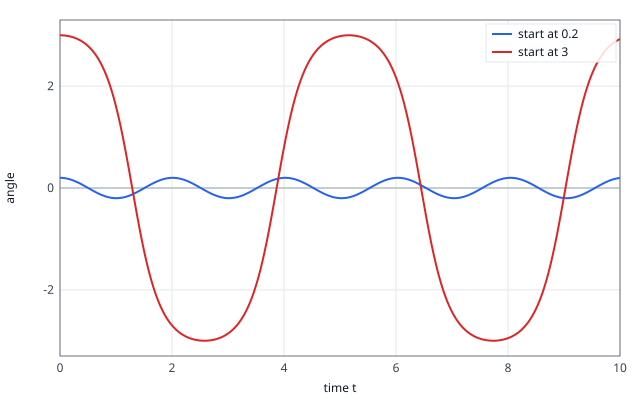

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
small = motion(th'^2/2 + 9.81*cos(th), th, t, 0.2, 0, 10);
big = motion(th'^2/2 + 9.81*cos(th), th, t, 3, 0, 10);
p = legend(plot(small.t, small.q), "start at 0.2");
p = show(p, legend(plot(big.t, big.q), "start at 3"));
labels(p, "time t", "angle")

The small swing repeats every $2\pi\sqrt{l/g} \approx 2.006$ seconds. The big one lingers near the top and takes much
longer: about 5.2 seconds. The note under `motion` reports how well the energy was kept, a useful check on the
numerical solution.

**Try this.** Start the pendulum at 3 radians with a small push, `v0 = 1`. What happens? (Compare its energy with the
energy $9.81$ needed to reach the top.)

## 4. Noether's theorem: missing coordinates, conserved momenta

A planet moves in the plane around the sun. In polar coordinates $(r, \varphi)$ its speed squared is
$r'^2 + r^2\varphi'^2$, and the potential is $-k/r$:

In [8]:
eulerlagrange(m*(r'^2 + r^2*f'^2)/2 + k/r, [r f], t)

[r'' == (f'^2*m*r^3-k)/(m*r^2), f'' == -2*f'*r'/r]

> Euler–Lagrange equations, one per unknown: d/dt(dL/dq') = dL/dq for each unknown q. A path that makes the integral of L smallest (or stationary) with fixed end points satisfies all of them. The equations are solved for the second derivatives. L does not contain f itself, so dL/df' = f'*m*r^2 stays constant along every extremal (a conserved momentum). L does not contain t itself, so energy(L, ...) = (f'^2*m*r^3-2*k+m*r*r'^2)/(2*r) stays constant along every extremal (Beltrami's identity, conservation of energy).

The note says that $L$ does not contain the angle $\varphi$ (here written `f`) itself, so $m r^2 \varphi'$ is
conserved: the **angular momentum**. That is Kepler's second law: the line from the sun to the planet sweeps out equal
areas in equal times. Emmy Noether proved in 1918 that this is a general rule: every symmetry of the Lagrangian
gives a conserved quantity. Rotations give angular momentum, shifts in space give momentum, shifts in time give
energy.

Simulate an orbit with $m = k = 1$, starting at distance 1 with sideways speed 1.2, and check the angular momentum
along the way:

1.14e-10

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

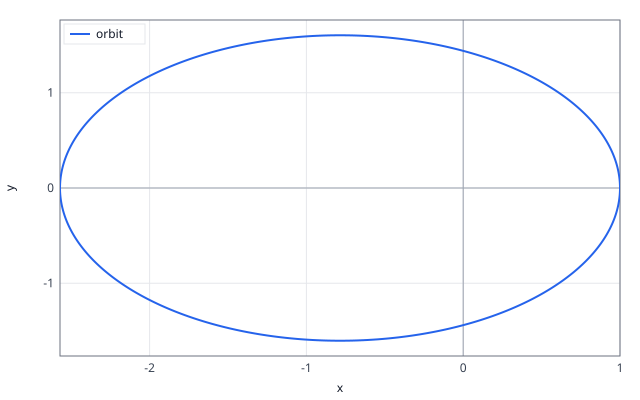

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [9]:
orbit = motion((r'^2 + r^2*f'^2)/2 + 1/r, [r f], t, [1 0], [0 1.2], 20);
Q = orbit.q;
V = orbit.v;
R = Q(1);
F = Q(2);
L1 = R.^2 .* V(2);
eval(max(L1) - min(L1), 3)
labels(legend(plot(R .* cos(F), R .* sin(F)), "orbit"), "x", "y")

The angular momentum stays $1.2$ to ten digits, and the orbit is a closed ellipse with the sun at a focus: Kepler's
first law, from a two-line Lagrangian.

**Try this.** Give the planet a sideways speed of 1.5 instead of 1.2. Then try `sqrt(2)`. What happens to the orbit
at the escape speed $\sqrt{2}$?

## 5. The double pendulum: chaos

Hang a second pendulum from the first. With two equal masses and rods of length 1 (and $g = 9.81$), the Lagrangian in
the two angles $a$ and $b$ is

$$L = a'^2 + \tfrac12 b'^2 + a' b' \cos(a - b) + 2g\cos a + g\cos b.$$

Deriving its equations of motion by hand takes a page; `motion` does it for you. Start it twice from almost the same
position: the lower arm at $2$ and at $2.000001$:

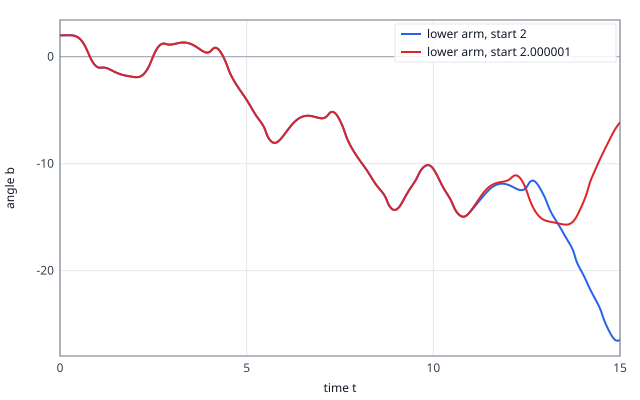

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [10]:
d1 = motion(a'^2 + b'^2/2 + a'*b'*cos(a - b) + 2*9.81*cos(a) + 9.81*cos(b), [a b], t, [2 2], [0 0], 15, 6000);
d2 = motion(a'^2 + b'^2/2 + a'*b'*cos(a - b) + 2*9.81*cos(a) + 9.81*cos(b), [a b], t, [2 2.000001], [0 0], 15, 6000);
A1 = d1.q;
A2 = d2.q;
p = legend(plot(d1.t, A1(2)), "lower arm, start 2");
p = show(p, legend(plot(d2.t, A2(2)), "lower arm, start 2.000001"));
labels(p, "time t", "angle b")

For about twelve seconds the two runs agree perfectly; then they separate and do completely different things. A difference
of one millionth of a radian grows until it is as large as the motion itself. This is **chaos**: the motion is fully
determined by the equations, yet unpredictable in practice, because no measurement is exact. The same happens in
the weather, as the [chaos](../chaos/README.md) path shows for the Lorenz system.

**Try this.** Start both runs at small angles, `[0.2 0.2]` and `[0.2 0.200001]`. Do they still separate?

## Summary

* The action is $S = \int (T - V)\,dt$; the true motion makes it stationary (usually smallest).
* `eulerlagrange` of $L = T - V$ gives Newton's equations in any coordinates.
* No $t$ in $L$: energy is conserved. A missing coordinate: its momentum $\partial L/\partial q'$ is conserved
  (Noether's theorem).
* `motion` simulates a system from its Lagrangian; the energy it reports is a check on the numbers.
* The double pendulum is chaotic: nearby starts separate exponentially.

This completes the path. The same principle continues in the [general relativity](../general-relativity/README.md)
path, where free particles follow geodesics, the paths of stationary length in curved spacetime.

## Exercises

1. **Free fall, minimised.** A stone is at height 10 at $t = 0$ and at height 0 at $t = 1$. Find its path with
   `extremal(y'^2/2 - 9.81*y, y, t, 0, 1, 10, 0)` and read off its height at $t = 1/2$ (point 51). Compare with
   $y = 10 + v_0 t - \tfrac g2 t^2$: what was the starting speed $v_0$?
2. **Spring energy.** For $L = \tfrac12 x'^2 - \tfrac12 x^2$, start `motion` at $x = 1$ at rest and run to $t = 2\pi$.
   Where is the mass? What does the note say about the energy?
3. **A charged particle.** In a magnetic field the Lagrangian of a particle in the plane can be written
   $L = \tfrac12(x'^2 + y'^2) + \tfrac{B}{2}(x y' - y x')$. Find the equations of motion. Which force appears?
4. **Pendulum periods.** Measure the period of the pendulum ($g/l = 9.81$) released from rest at $0.2$, $1$, $2$ and
   $3$ radians. How does it grow?
5. **Escape.** In section 4, which sideways speed gives a circular orbit? (Set $r'' = 0$ at $r = 1$.)

## Hints and answers

* **Section 1, Try this.** $0$: no kinetic and no potential energy. That is more than $-32.08$, so the true path wins.
* **Section 2, Try this.** $L = \tfrac12 x'^2(1 + 4x^2) - g x^2$; `eulerlagrange` gives
  $x'' = -(4x x'^2 + 2gx)/(1 + 4x^2)$.
* **Section 3, Try this.** Its energy is $\tfrac12 - 9.81\cos 3 \approx 10.2$, more than $9.81$: the pendulum goes over
  the top and keeps turning around, so the angle keeps growing.
* **Section 4, Try this.** At 1.5 the ellipse is longer; at $\sqrt 2$ the energy is 0 and the orbit becomes a parabola
  that never comes back.
* **Section 5, Try this.** For small angles the motion is nearly regular and the two runs stay close (the difference
  stays around a millionth).
* **Exercise 1.** About $6.23$ at $t = 1/2$; $v_0 = -10 + g/2 \approx -5.1$: thrown downwards at about $5.1$ m/s.
* **Exercise 2.** Back at $x = 1$ (one full period); the energy is kept to about ten digits.
* **Exercise 3.** $x'' = B y'$, $y'' = -B x'$: the Lorentz force, perpendicular to the velocity. The particle moves
  in circles.
* **Exercise 4.** About $2.01$, $2.13$, $2.66$ and $5.16$ seconds: the period grows slowly at first and without bound
  as the start approaches $\pi$.
* **Exercise 5.** Speed 1: then $r'' = r\varphi'^2 - 1/r^2 = 0$ at $r = 1$.

## Sources

1. P.-L. Moreau de Maupertuis, "Accord de différentes lois de la nature qui avaient jusqu'ici paru incompatibles",
   *Mémoires de l'Académie Royale des Sciences de Paris* (1744), 417–426.
2. J.-L. Lagrange, *Mécanique analytique*, Desaint, Paris (1788).
3. W. R. Hamilton, "On a general method in dynamics", *Philosophical Transactions of the Royal Society* 124 (1834),
   247–308.
4. E. Noether, "Invariante Variationsprobleme", *Nachrichten von der Gesellschaft der Wissenschaften zu Göttingen* (1918),
   235–257.
5. R. P. Feynman, R. B. Leighton and M. Sands, *The Feynman Lectures on Physics*, vol. 2, Addison-Wesley (1964),
   chapter 19 ("The principle of least action").